# State data: exploratory analysis

**Aim:** explore naming concentration over time, differences across states, and selected name–sex trajectories. Run after `01_state_preparation.ipynb`, which creates the prepared dataset used here.

All shares refer to **published SSA counts**, not all births. State totals are not the separate national dataset. The analysis is descriptive; repeated states, names and years are not independent observations. Original acquisition provenance remains unresolved.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# Find the project folder when running from the course folder or notebooks/.
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
elif (ROOT / 'group_project_dsfm').is_dir():
    ROOT = ROOT / 'group_project_dsfm'

FIGURES = ROOT / 'reports/figures'
TABLES = ROOT / 'reports/tables'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# Load the prepared columns used below. Compact types reduce memory use.
dtypes = {'state': 'category', 'sex': 'category', 'year': 'int16',
          'name': 'string', 'count': 'int64', 'rank': 'int32'}
data = pd.read_csv(ROOT / 'data/processed/state_names.csv.gz',
                   usecols=list(dtypes), dtype=dtypes, keep_default_na=False)
# keep_default_na=False preserves names that resemble missing-value labels.
assert data['count'].ge(5).all(), 'Published state counts should be at least five.'
print(f'Loaded {len(data):,} records.')

# Use the same colours and formatting in the three figures.
COLORS = {'F': '#39566f', 'M': '#777777'}
INK, MUTED, GRID = '#222222', '#666666', '#e6e6e6'
plt.rcParams.update({
    'figure.dpi': 140, 'savefig.dpi': 180, 'font.family': 'DejaVu Sans',
    'font.size': 11, 'text.color': INK, 'axes.labelcolor': MUTED,
    'axes.titlesize': 12, 'axes.titleweight': 'normal', 'axes.titlelocation': 'left',
    'axes.edgecolor': GRID, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.spines.left': False, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.major.size': 0, 'ytick.major.size': 0, 'grid.color': GRID,
    'axes.axisbelow': True, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'savefig.bbox': 'tight'
})

Loaded 6,696,687 records.


## 1. Naming concentration through time

For each state–sex–year, **top-10 concentration** is the combined count for its ten highest-ranked names divided by all published counts in that group. Smaller values indicate a less concentrated *published* distribution. Ranks use count descending, then alphabetical order for ties.

The line is the median across 51 states/DC; the band is the interquartile range. Every state receives equal weight. Rare-name suppression affects denominators, particularly for smaller states, so differences are descriptive. Years before 1937 are shaded because early SSA coverage is less complete.

,year,sex,published_count,distinct_names,median_top10,q25_top10,q75_top10
0,1950,F,1610017,2112,0.2798,0.2636,0.2975
1,1950,M,1720112,1721,0.3631,0.3336,0.3923
2,1980,F,1462212,3685,0.2219,0.2073,0.2467
3,1980,M,1668069,2502,0.2723,0.2615,0.2934
4,2025,F,1303470,5349,0.0962,0.0898,0.1192
5,2025,M,1466284,4368,0.1054,0.0997,0.1263


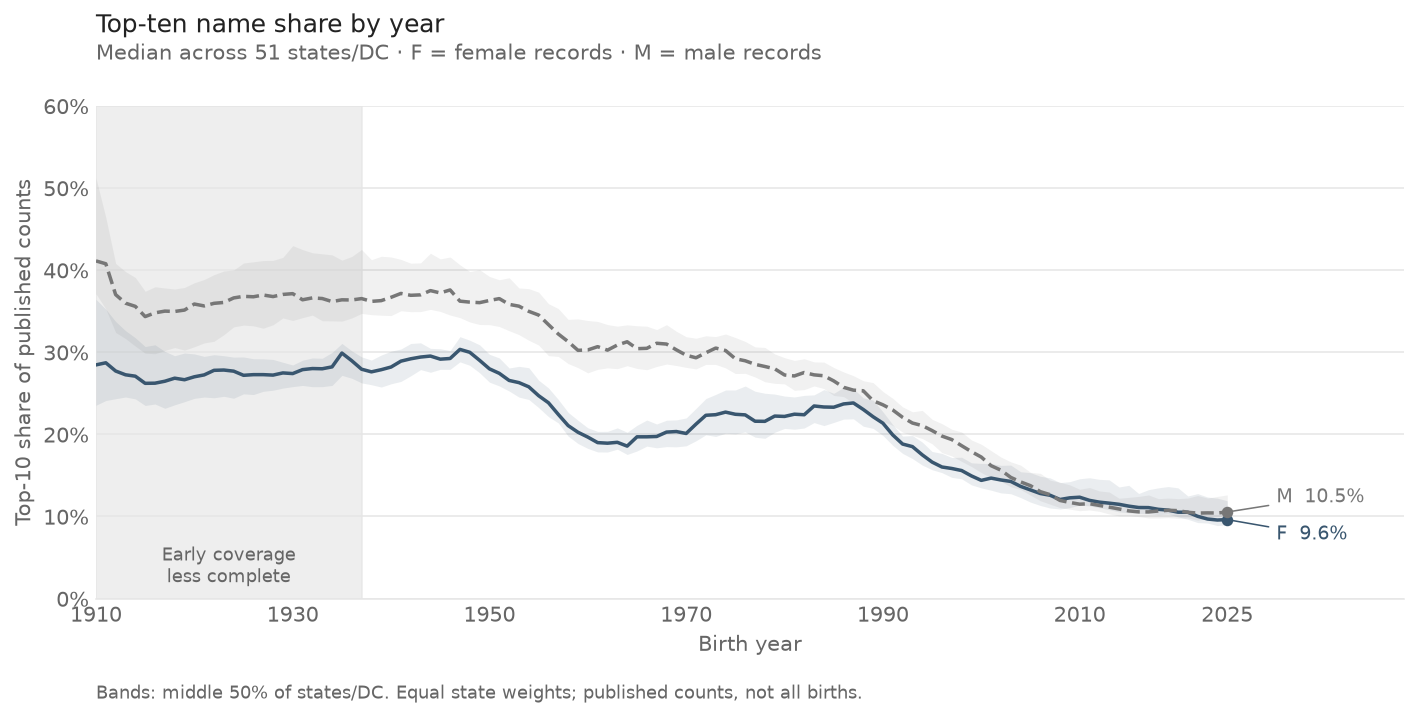

In [2]:
GROUP = ['state', 'sex', 'year']
group_stats = data.groupby(GROUP, observed=True).agg(
    published_count=('count', 'sum'), published_names=('name', 'size'))
top10 = data.loc[data['rank'].le(10)].groupby(GROUP, observed=True)['count'].sum()
group_stats['top10_share'] = top10 / group_stats['published_count']
assert group_stats['top10_share'].notna().all()
assert group_stats['top10_share'].between(0, 1).all()
assert group_stats['published_count'].sum() == data['count'].sum()

# State medians describe a typical state rather than a population-weighted total.
trend = group_stats.groupby(['year', 'sex'], observed=True).agg(
    median_top10=('top10_share', 'median'),
    q25_top10=('top10_share', lambda values: values.quantile(0.25)),
    q75_top10=('top10_share', lambda values: values.quantile(0.75)))
pooled = data.groupby(['year', 'sex'], observed=True).agg(
    published_count=('count', 'sum'), distinct_names=('name', 'nunique'))
summary = pooled.join(trend)
anchor_table = summary.loc[summary.index.get_level_values('year').isin([1950, 1980, 2025])].reset_index()
display(anchor_table.round(4))

# Plot the median and middle 50% of states for each year.
fig, ax = plt.subplots(figsize=(10.5, 5.1))
for sex in ['F', 'M']:
    values = trend.xs(sex, level='sex')
    years = values.index.to_numpy()
    ax.fill_between(years, values['q25_top10'].to_numpy(), values['q75_top10'].to_numpy(),
                    color=COLORS[sex], alpha=0.10, linewidth=0)
    ax.plot(years, values['median_top10'].to_numpy(), color=COLORS[sex], linewidth=1.8,
            linestyle='-' if sex == 'F' else '--')
    endpoint = float(values.loc[2025, 'median_top10'])
    ax.scatter([2025], [endpoint], color=COLORS[sex], s=24, zorder=4)
    ax.annotate(f'{sex}  {endpoint:.1%}', xy=(2025, endpoint),
                xytext=(2030, endpoint + (0.018 if sex == 'M' else -0.018)),
                color=COLORS[sex], weight='normal', fontsize=10, va='center',
                arrowprops={'arrowstyle': '-', 'color': COLORS[sex], 'lw': 0.8})
ax.axvspan(1910, 1937, color=GRID, alpha=0.65, zorder=0)
ax.text(1923.5, 0.02, 'Early coverage\nless complete', ha='center', color=MUTED, fontsize=9)
ax.set(xlabel='Birth year', ylabel='Top-10 share of published counts', xlim=(1910, 2043), ylim=(0, 0.60))
ax.set_xticks([1910, 1930, 1950, 1970, 1990, 2010, 2025])
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis='y', linewidth=0.8)
fig.suptitle('Top-ten name share by year',
             x=0.09, y=0.98, ha='left', fontsize=13, weight='normal', color=INK)
fig.text(0.09, 0.915, 'Median across 51 states/DC · F = female records · M = male records',
         color=MUTED, fontsize=11)
fig.text(0.09, 0.02, 'Bands: middle 50% of states/DC. Equal state weights; published counts, not all births.',
         color=MUTED, fontsize=9.5)
fig.subplots_adjust(left=0.09, right=0.98, top=0.85, bottom=0.16)
fig.savefig(FIGURES / 'concentration_over_time.png')
plt.show()

## 2. Differences across states

Compare the same concentration measure in **2025**, keeping female and male records separate. States/DC are ordered by their mean of the two concentrations for readability; connecting lines pair the categories within one state. This is not a causal comparison or a ranking of all-birth name diversity.

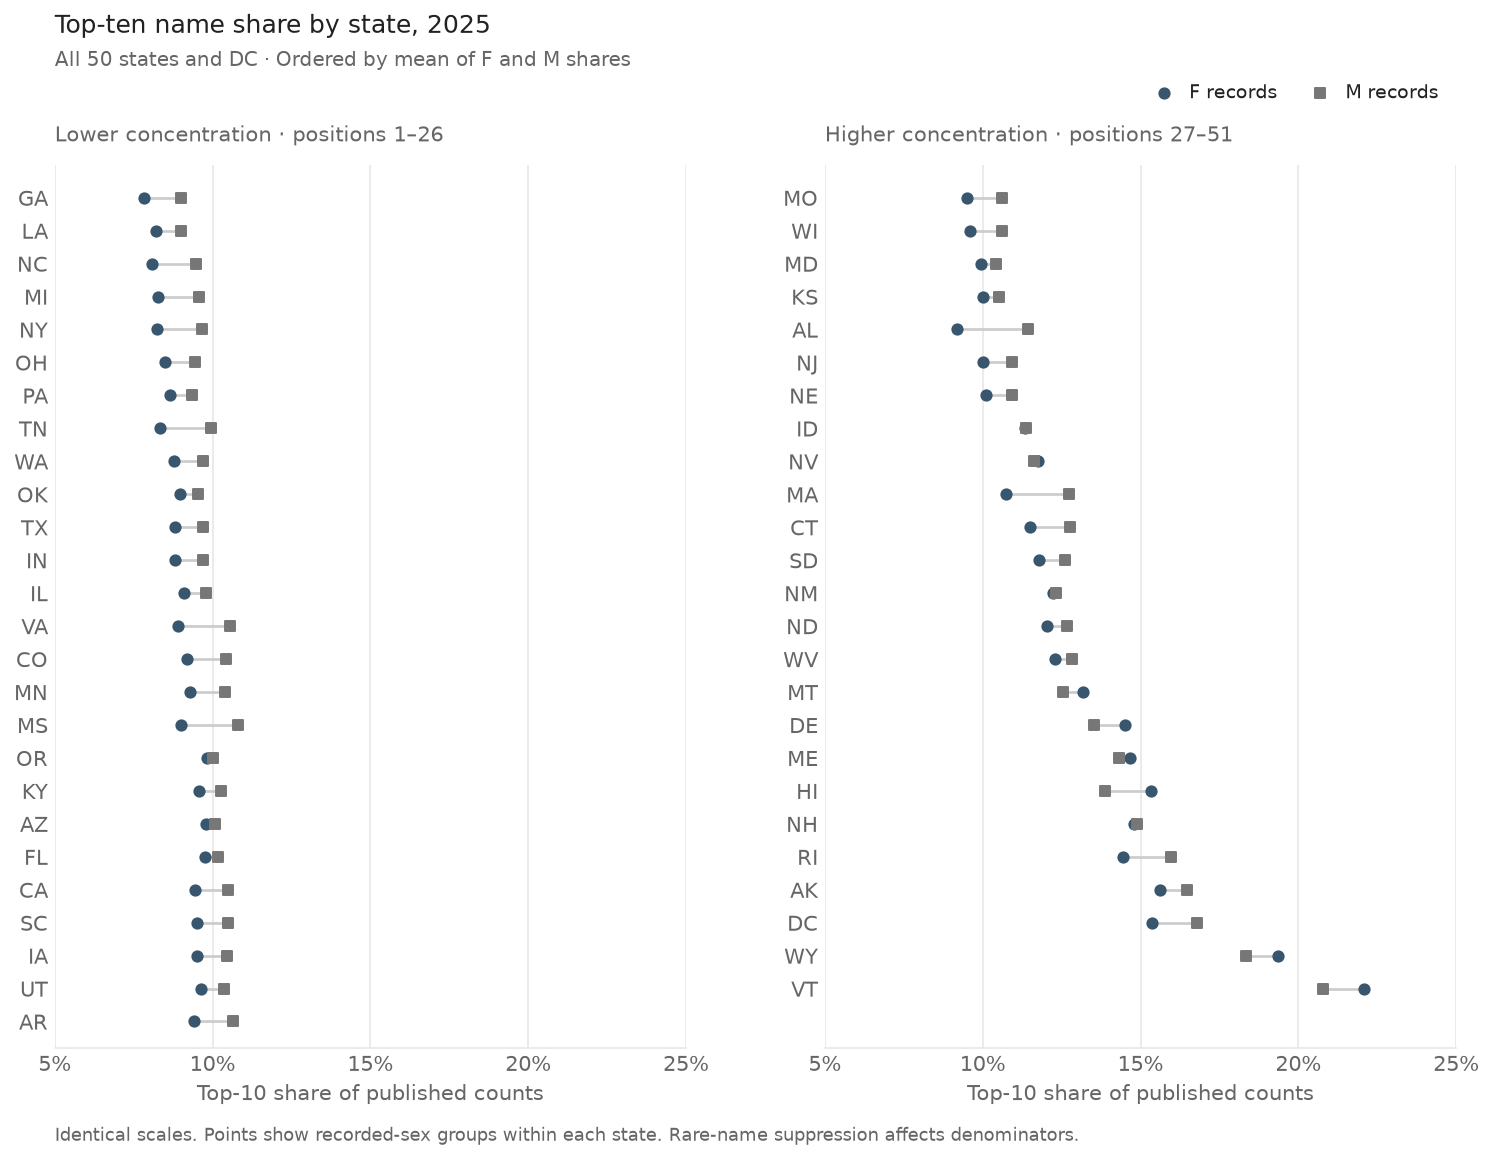

sex,F,M
min,0.0783,0.0900
median,0.0962,0.1054
max,0.2207,0.2079


In [3]:
latest = group_stats.xs(2025, level='year')['top10_share'].unstack('sex')
assert latest.shape == (51, 2) and latest.notna().all().all()
latest = latest.loc[latest.mean(axis=1).sort_values().index]
# Split the ordered list for readability; both panels use exactly the same scale.
fig, axes = plt.subplots(1, 2, figsize=(11, 8.3), sharex=True)
for ax, section, label in zip(axes, [latest.iloc[:26], latest.iloc[26:]],
                              ['Lower concentration · positions 1–26', 'Higher concentration · positions 27–51']):
    y = list(range(len(section)))
    ax.hlines(y, section['F'], section['M'], color='#cccccc', linewidth=1.4)
    for sex in ['F', 'M']:
        ax.scatter(section[sex], y, label=f'{sex} records', color=COLORS[sex], s=28, zorder=3,
                   marker='o' if sex == 'F' else 's')
    ax.set_yticks(y, labels=section.index.astype(str))
    ax.set_ylim(25.8, -1)
    ax.set(xlabel='Top-10 share of published counts', xlim=(0.05, 0.25))
    ax.set_xticks([0.05, 0.10, 0.15, 0.20, 0.25])
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(label, fontsize=11, pad=12, color=MUTED, weight='normal')
    ax.grid(axis='x', linewidth=0.8)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.98, 0.945),
           frameon=False, ncol=2, fontsize=10, handletextpad=0.3, columnspacing=1.2)
fig.suptitle('Top-ten name share by state, 2025', x=0.07, y=0.99,
             ha='left', fontsize=13, weight='normal', color=INK)
fig.text(0.07, 0.945, 'All 50 states and DC · Ordered by mean of F and M shares',
         color=MUTED, fontsize=10.5)
fig.text(0.07, 0.02, 'Identical scales. Points show recorded-sex groups within each state. Rare-name suppression affects denominators.',
         color=MUTED, fontsize=9)
fig.subplots_adjust(left=0.07, right=0.98, top=0.86, bottom=0.10, wspace=0.22)
fig.savefig(FIGURES / 'state_concentration_2025.png')
plt.show()
display(latest.agg(['min', 'median', 'max']).round(4))

## 3. Selected name–sex trajectories in California

**Ashley, Leslie, Taylor and Jordan** are hand-picked illustrations, not a representative sample or a test of which names changed most. Restricting to one large state avoids combining changing sets of reporting states.

For each name–year, calculate `F / (F + M)` only if **both recorded-sex counts are published** and their combined count is at least **100**. This pragmatic threshold reduces the influence of very small denominators; it is not a statistical significance threshold. Unavailable pairs remain gaps, never zeros.

The endpoint summaries average eligible annual shares in **1980–1989 and 2000–2009**, requiring at least five eligible years per name in each window. These windows were selected **after inspecting record availability**: the original 1950–1959 versus 2016–2025 comparison was not estimable for any of the four examples under this rule. The full 1910–2025 trajectories remain visible. These are exploratory, selected comparisons of recorded-sex associations, not representative conclusions or individual gender identities.

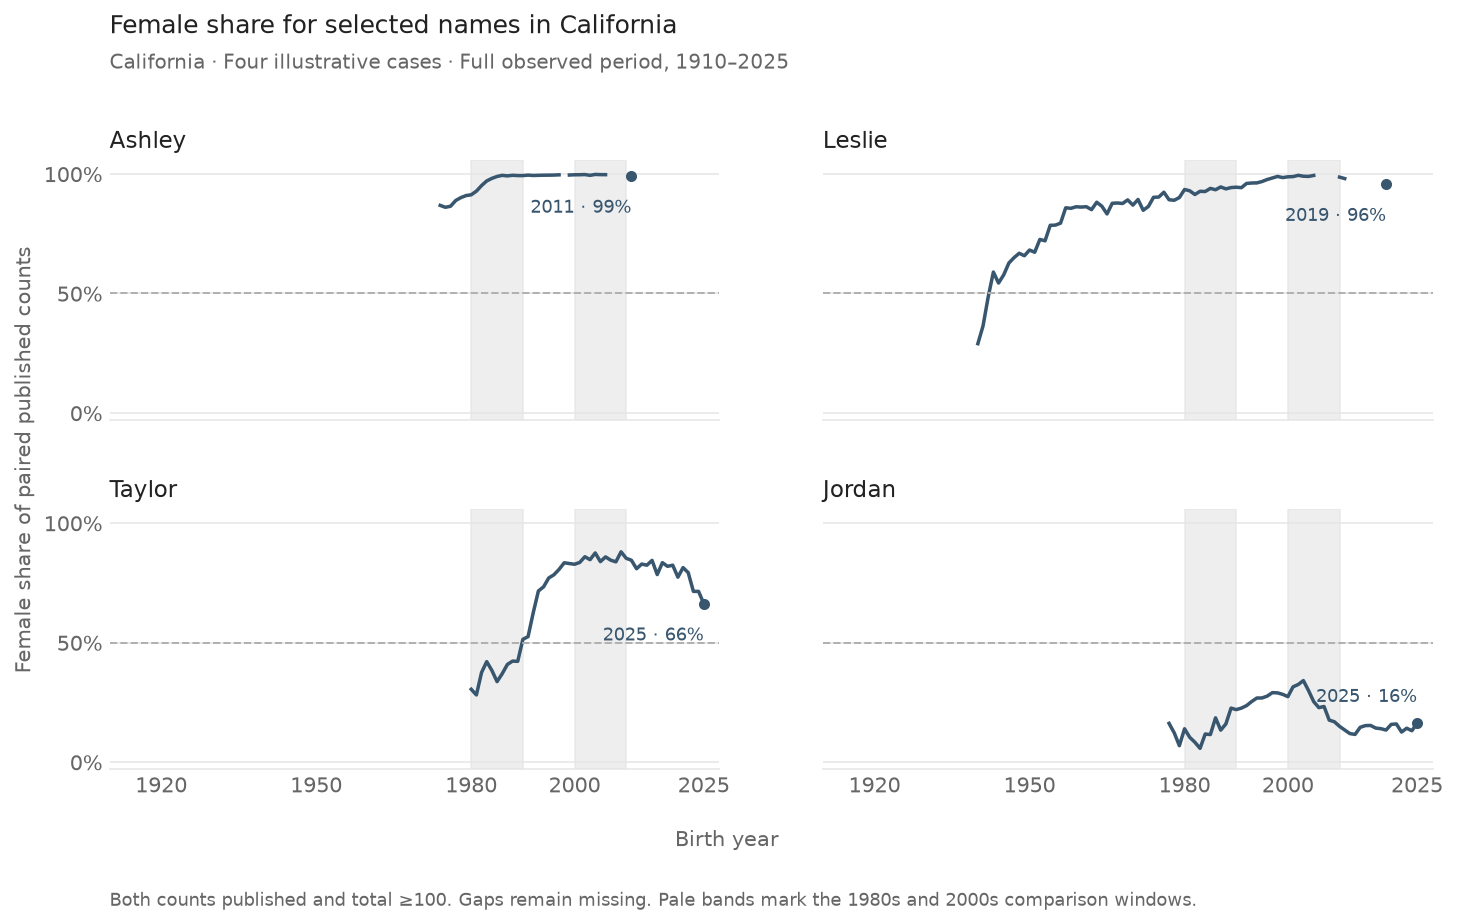

,name,eligible_years,eligible_years_1980s,eligible_years_2000s,female_share_1980s,female_share_2000s,change_percentage_points
0,Ashley,33,10,7,0.971,0.997,2.596
1,Leslie,73,10,7,0.933,0.990,5.682
2,Taylor,46,10,10,0.372,0.850,47.800
3,Jordan,49,10,10,0.132,0.261,12.910


In [4]:
EXAMPLES = ['Ashley', 'Leslie', 'Taylor', 'Jordan']
selected = data.loc[data['state'].eq('CA') & data['name'].isin(EXAMPLES)]
pairs = selected.pivot(index=['name', 'year'], columns='sex', values='count')
# Reindexing creates explicit gaps; it does not impute suppressed observations.
grid = pd.MultiIndex.from_product([EXAMPLES, range(1910, 2026)], names=['name', 'year'])
pairs = pairs.reindex(grid).reindex(columns=['F', 'M'])
both = pairs[['F', 'M']].notna().all(axis=1)
totals = pairs[['F', 'M']].sum(axis=1, min_count=2)
eligible = both & totals.ge(100)
pairs['female_share'] = (pairs['F'] / totals).where(eligible)
assert pairs.loc[~eligible, 'female_share'].isna().all()
assert pairs['female_share'].dropna().between(0, 1).all()

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.5), sharex=True, sharey=True)
endpoint_rows = []
for name, ax in zip(EXAMPLES, axes.flat):
    series = pairs.xs(name)['female_share']
    ax.plot(series.index, series.to_numpy(), color=COLORS['F'], linewidth=1.8)
    ax.axhline(0.5, color='#b0b0b0', linewidth=1, linestyle='--')
    for left, right in [(1980, 1990), (2000, 2010)]:
        ax.axvspan(left, right, color=GRID, alpha=0.65, zorder=0)
    ax.set(title=name, ylim=(-0.03, 1.06), xlim=(1910, 2028))
    ax.set_xticks([1920, 1950, 1980, 2000, 2025])
    ax.set_yticks([0, 0.5, 1])
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis='y', linewidth=0.8)
    visible = series.dropna()
    ax.scatter([visible.index[-1]], [visible.iloc[-1]], color=COLORS['F'], s=22, zorder=4)
    ax.annotate(f'{visible.index[-1]} · {visible.iloc[-1]:.0%}',
                xy=(visible.index[-1], visible.iloc[-1]),
                xytext=(0, -19 if visible.iloc[-1] > 0.4 else 11),
                textcoords='offset points', ha='right', color=COLORS['F'], fontsize=9.5)
    # These common windows were selected after checking eligible-year coverage.
    earlier, later = series.loc[1980:1989].dropna(), series.loc[2000:2009].dropna()
    assert len(earlier) >= 5 and len(later) >= 5, f'Insufficient endpoint coverage: {name}'
    earlier_mean, later_mean = float(earlier.mean()), float(later.mean())
    endpoint_rows.append({'name': name, 'eligible_years': int(series.notna().sum()),
                          'eligible_years_1980s': len(earlier), 'eligible_years_2000s': len(later),
                          'female_share_1980s': earlier_mean, 'female_share_2000s': later_mean,
                          'change_percentage_points': 100 * (later_mean - earlier_mean)})
fig.supxlabel('Birth year', y=0.07, fontsize=11, color=MUTED)
fig.supylabel('Female share of paired published counts', x=0.015, fontsize=11, color=MUTED)
fig.suptitle('Female share for selected names in California',
             x=0.08, y=0.99, ha='left', fontsize=13, weight='normal', color=INK)
fig.text(0.08, 0.93, 'California · Four illustrative cases · Full observed period, 1910–2025',
         color=MUTED, fontsize=10.5)
fig.text(0.08, 0.01, 'Both counts published and total ≥100. Gaps remain missing. Pale bands mark the 1980s and 2000s comparison windows.',
         color=MUTED, fontsize=9)
fig.subplots_adjust(left=0.08, right=0.98, top=0.83, bottom=0.16, hspace=0.34, wspace=0.17)
fig.savefig(FIGURES / 'name_sex_trajectories.png')
plt.show()
endpoints = pd.DataFrame(endpoint_rows)
display(endpoints.round(3))

## 4. Save the tables

Save the three result tables as CSV files. The figures are saved in the plotting cells above.

The report text in `reports/_update_results.md` is maintained separately. If the data or analysis changes, check its numbers and interpretations against these outputs before rendering the report.

In [5]:
anchor_table.to_csv(TABLES / 'eda_summary.csv', index=False)
latest.rename_axis('state').reset_index().to_csv(TABLES / 'state_concentration_2025.csv', index=False)
endpoints.to_csv(TABLES / 'name_sex_endpoints.csv', index=False)
print('Saved the three result tables in reports/tables/.')

Saved the three result tables in reports/tables/.
